In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
from google.colab import files

archivo = files.upload()

Saving DATASET_INmuebles.xlsx to DATASET_INmuebles (2).xlsx


In [10]:
df = pd.read_excel("DATASET_INmuebles.xlsx")

print("Dimensiones del conjunto de datos:")
print(df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nPrimeros cinco registros:")
display(df.head())

Dimensiones del conjunto de datos:
(1000, 10)

Nombres de las columnas:
['Inmueble', 'Área m²', 'Habitaciones', 'Estrato', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']

Primeros cinco registros:


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


### Exploración inicial del conjunto de datos

En esta etapa se carga y examina el conjunto de datos de inmuebles en arriendo proporcionado para la actividad. Se identifican las dimensiones del archivo, los nombres de las variables, los tipos de datos y los posibles valores faltantes. Esta revisión permite conocer la estructura de la información antes de realizar el preprocesamiento y aplicar los algoritmos de aprendizaje no supervisado.

In [4]:
# Exploración inicial de los datos

print("Información general del dataset:")
df.info()

print("\nCantidad de valores faltantes por columna:")
print(df.isnull().sum())

print("\nValores únicos de las variables categóricas:")
print("Localidad:", df["Localidad"].unique())
print("Tipo Inmueble:", df["Tipo Inmueble"].unique())

print("\nValores únicos de las columnas de estrato:")
print("Estrato:", sorted(df["Estrato"].unique()))
print("Estrato.1:", sorted(df["Estrato.1"].unique()))

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Inmueble         1000 non-null   object
 1   Área m²          1000 non-null   int64 
 2   Habitaciones     1000 non-null   int64 
 3   Estrato          1000 non-null   int64 
 4   Precio arriendo  1000 non-null   int64 
 5   Baños            1000 non-null   int64 
 6   Antig[uedad      1000 non-null   int64 
 7   Localidad        1000 non-null   object
 8   Tipo Inmueble    1000 non-null   object
 9   Estrato.1        1000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 78.3+ KB

Cantidad de valores faltantes por columna:
Inmueble           0
Área m²            0
Habitaciones       0
Estrato            0
Precio arriendo    0
Baños              0
Antig[uedad        0
Localidad          0
Tipo Inmueble      0
Estrato.1          0
dtype: int64

Va

### Selección de variables

Durante la exploración se identificaron dos columnas relacionadas con el estrato: `Estrato` y `Estrato.1`. Para evitar incluir ambas variables en el análisis, se decidió retirar la columna `Estrato` y conservar `Estrato.1`. Esta modificación se realiza sobre el DataFrame de trabajo, sin alterar el archivo Excel original.

In [11]:
# Eliminar la columna Estrato del DataFrame de trabajo
df = df.drop(columns=["Estrato"])

# Verificar las columnas restantes
print("Columnas después de eliminar Estrato:")
print(df.columns.tolist())

print("\nDimensiones actualizadas:")
print(df.shape)

Columnas después de eliminar Estrato:
['Inmueble', 'Área m²', 'Habitaciones', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']

Dimensiones actualizadas:
(1000, 9)


**Resultado de la selección de variables**

Después de excluir la columna `Estrato`, se verificó que el conjunto de datos conserva 1.000 registros y queda conformado por 9 columnas. Se mantiene la variable `Estrato.1` para continuar con la revisión y preparación de las características que se utilizarán en los algoritmos de aprendizaje no supervisado.

In [12]:
# Revisar los tipos de datos después de la selección de variables
print("Tipos de datos actualizados:")
print(df.dtypes)

print("\nResumen estadístico de las variables numéricas:")
display(df.describe())

Tipos de datos actualizados:
Inmueble           object
Área m²             int64
Habitaciones        int64
Precio arriendo     int64
Baños               int64
Antig[uedad         int64
Localidad          object
Tipo Inmueble      object
Estrato.1           int64
dtype: object

Resumen estadístico de las variables numéricas:


,Área m²,Habitaciones,Precio arriendo,Baños,Antig[uedad,Estrato.1
count,1000.000000,1000.000000,1.000000e+03,1000.00000,1000.000000,1000.00000
mean,96.727000,2.664000,3.633287e+06,1.48000,8.459000,2.47900
std,54.100104,1.279352,2.438534e+06,0.49985,2.347302,1.11481
min,30.000000,1.000000,7.024800e+05,1.00000,5.000000,1.00000
25%,55.000000,2.000000,1.644060e+06,1.00000,6.000000,1.00000
50%,80.500000,2.000000,2.930804e+06,1.00000,8.500000,2.00000
75%,135.000000,4.000000,5.394807e+06,2.00000,10.000000,3.00000
max,220.000000,5.000000,8.988836e+06,2.00000,12.000000,4.00000


### Análisis estadístico inicial

Se calcularon estadísticas descriptivas para conocer la distribución y el rango de las variables numéricas. El área de los inmuebles presenta valores entre 30 y 220 m², mientras que el precio de arriendo registra valores entre 702.480 y 8.988.836. También se identificaron diferencias de escala entre las variables, aspecto que deberá considerarse durante el preprocesamiento previo a la aplicación de K-Means.

In [13]:
# Revisar la distribución de las variables categóricas

print("Cantidad de inmuebles por localidad:")
print(df["Localidad"].value_counts())

print("\nCantidad de inmuebles por tipo:")
print(df["Tipo Inmueble"].value_counts())

Cantidad de inmuebles por localidad:
Localidad
Suba         334
Chapinero    333
Usaquén      333
Name: count, dtype: int64

Cantidad de inmuebles por tipo:
Tipo Inmueble
Apto             334
Casa             333
ApartaEstudio    333
Name: count, dtype: int64


### Preparación de las variables para K-Means

En esta etapa se seleccionan las características que se utilizarán para segmentar los inmuebles. Se excluye el identificador, ya que su función es reconocer cada registro y no medir similitudes entre propiedades. Las variables categóricas se prepararán mediante codificación numérica y las variables seleccionadas se escalarán antes de entrenar el modelo.

In [14]:
# Seleccionar las variables para el análisis

columnas_numericas = [
    "Área m²",
    "Habitaciones",
    "Precio arriendo",
    "Baños",
    "Antig[uedad",
    "Estrato.1"
]

columnas_categoricas = [
    "Localidad",
    "Tipo Inmueble"
]

print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

Variables numéricas:
['Área m²', 'Habitaciones', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Estrato.1']

Variables categóricas:
['Localidad', 'Tipo Inmueble']


In [15]:
from sklearn.preprocessing import OneHotEncoder

# Preparar las variables categóricas
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

datos_categoricos = encoder.fit_transform(df[columnas_categoricas])

# Mostrar las categorías identificadas
print("Categorías codificadas:")
print(encoder.get_feature_names_out(columnas_categoricas))

print("\nDimensiones de los datos categóricos:")
print(datos_categoricos.shape)

Categorías codificadas:
['Localidad_Chapinero' 'Localidad_Suba' 'Localidad_Usaquén'
 'Tipo Inmueble_ApartaEstudio' 'Tipo Inmueble_Apto' 'Tipo Inmueble_Casa']

Dimensiones de los datos categóricos:
(1000, 6)


### Codificación de las variables categóricas

Las variables Localidad y Tipo Inmueble contienen información categórica que debe transformarse a un formato numérico para utilizarse en K-Means. Para ello, se aplicó OneHotEncoder de Scikit-learn, que representa cada categoría mediante una columna binaria. Como resultado, se obtuvieron seis columnas categóricas para los 1.000 inmuebles, correspondientes a las tres localidades y los tres tipos de inmueble identificados en el conjunto de datos.

### Integración de las variables

Una vez codificadas las variables categóricas, se combinan con las variables numéricas seleccionadas. De esta manera, se construye una matriz que integra las características físicas, económicas y geográficas de los inmuebles. El identificador se mantiene fuera de esta matriz porque no debe utilizarse para calcular las distancias entre propiedades.

In [16]:
# Combinar las variables numéricas y categóricas

datos_numericos = df[columnas_numericas].to_numpy()

X = np.hstack([
    datos_numericos,
    datos_categoricos
])

print("Dimensiones de la matriz combinada:")
print(X.shape)

print("\nCantidad de características:")
print(X.shape[1])

Dimensiones de la matriz combinada:
(1000, 12)

Cantidad de características:
12


### Escalamiento de las variables numéricas

Las variables numéricas presentan diferentes escalas de medición, especialmente el precio de arriendo frente al número de habitaciones, baños y estrato. Para evitar que las diferencias de magnitud dominen el cálculo de distancias, se aplica StandardScaler a las variables numéricas. Posteriormente, las variables estandarizadas se integran nuevamente con las variables categóricas codificadas para construir la matriz final de características.

In [17]:
from sklearn.preprocessing import StandardScaler

# Estandarizar las variables numéricas
scaler = StandardScaler()
datos_numericos_escalados = scaler.fit_transform(
    df[columnas_numericas]
)

# Combinar las variables escaladas con las categóricas
X_escalado = np.hstack([
    datos_numericos_escalados,
    datos_categoricos
])

print("Dimensiones de la matriz escalada:")
print(X_escalado.shape)

print("\nMedias de las variables numéricas escaladas:")
print(np.round(datos_numericos_escalados.mean(axis=0), 3))

print("\nDesviaciones estándar de las variables numéricas escaladas:")
print(np.round(datos_numericos_escalados.std(axis=0), 3))

Dimensiones de la matriz escalada:
(1000, 12)

Medias de las variables numéricas escaladas:
[-0. -0. -0.  0.  0. -0.]

Desviaciones estándar de las variables numéricas escaladas:
[1. 1. 1. 1. 1. 1.]


### Resultado del escalamiento

Se aplicó StandardScaler a las seis variables numéricas seleccionadas. La comprobación posterior mostró medias cercanas a cero y desviaciones estándar iguales a uno. Posteriormente, las variables estandarizadas se combinaron con las variables categóricas codificadas, obteniendo una matriz de 1.000 registros y 12 características para continuar con el análisis de clustering.

### Implementación de K-Means

Se utiliza el algoritmo K-Means para agrupar los inmuebles de acuerdo con la similitud de sus características. Como primera prueba, se configura el modelo con dos clústeres, una semilla aleatoria de 42 y diez inicializaciones. Esta configuración permite obtener una primera segmentación del portafolio inmobiliario, que posteriormente se comparará con un modelo de cuatro clústeres.

In [18]:
from sklearn.cluster import KMeans

# Crear y entrenar el primer modelo
modelo_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

etiquetas_2 = modelo_2.fit_predict(X_escalado)

print("Cantidad de clústeres:", len(set(etiquetas_2)))
print("\nCantidad de inmuebles por clúster:")
print(pd.Series(etiquetas_2).value_counts().sort_index())

Cantidad de clústeres: 2

Cantidad de inmuebles por clúster:
0    381
1    619
Name: count, dtype: int64


### Resultado inicial de K-Means con dos clústeres

El modelo K-Means se ejecutó con dos clústeres, `random_state=42` y `n_init=10`. La segmentación asignó 381 inmuebles al clúster 0 y 619 al clúster 1. Esta distribución muestra que los grupos tienen tamaños diferentes; sin embargo, su interpretación comercial requiere analizar las características promedio de cada segmento.

### Caracterización de los segmentos

Para interpretar los grupos obtenidos, se calculan estadísticas descriptivas de las variables numéricas originales según el clúster asignado. Este procedimiento permite comparar las características físicas y económicas de los segmentos en sus unidades originales y facilita su interpretación comercial.

In [19]:
# Caracterizar los clústeres con los datos originales

df["Cluster_2"] = etiquetas_2

resumen_2 = df.groupby("Cluster_2")[columnas_numericas].mean().round(2)

display(resumen_2)

,Área m²,Habitaciones,Precio arriendo,Baños,Antig[uedad,Estrato.1
Cluster_2,,,,,,
0,154.74,4.01,6304975.03,1.50,8.34,2.51
1,61.02,1.83,1988838.77,1.47,8.53,2.46


### Interpretación de los segmentos con dos clústeres

La caracterización de los grupos muestra diferencias importantes en el área, el número de habitaciones y el precio promedio de arriendo. El clúster 0 reúne inmuebles de mayor tamaño y precio, mientras que el clúster 1 agrupa propiedades de menor área y menor costo de arrendamiento. En contraste, las diferencias promedio en baños, antigüedad y estrato reportado son reducidas. Estos resultados permiten identificar dos perfiles comerciales preliminares dentro del portafolio inmobiliario.

### Modelo K-Means con cuatro clústeres

Para evaluar una segmentación más detallada, se configura un segundo modelo con cuatro clústeres, manteniendo `random_state=42` y `n_init=10`. La comparación con el modelo de dos clústeres permitirá determinar si una mayor cantidad de grupos ayuda a identificar perfiles comerciales más específicos.

In [20]:
# Crear y entrenar el modelo con cuatro clústeres

modelo_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

etiquetas_4 = modelo_4.fit_predict(X_escalado)

print("Cantidad de clústeres:", len(set(etiquetas_4)))
print("\nCantidad de inmuebles por clúster:")
print(pd.Series(etiquetas_4).value_counts().sort_index())

Cantidad de clústeres: 4

Cantidad de inmuebles por clúster:
0    189
1    328
2    291
3    192
Name: count, dtype: int64


### Distribución de los inmuebles en cuatro clústeres

El segundo modelo K-Means se ejecutó con cuatro clústeres, manteniendo `random_state=42` y `n_init=10`. Los resultados asignaron 189 inmuebles al clúster 0, 328 al clúster 1, 291 al clúster 2 y 192 al clúster 3. Esta configuración permite explorar una segmentación más detallada del portafolio, cuya utilidad comercial se evaluará mediante la caracterización de cada grupo.

### Caracterización de los segmentos con cuatro clústeres

Para interpretar la segmentación, se calculan los promedios de las variables numéricas originales para cada grupo identificado por K-Means. La comparación permitirá reconocer las características físicas y económicas de cada segmento y evaluar si la división en cuatro grupos aporta información comercial adicional frente al modelo de dos clústeres.

In [21]:
# Guardar las etiquetas del modelo de cuatro clústeres
df["Cluster_4"] = etiquetas_4

# Calcular los promedios de las variables numéricas por clúster
resumen_4 = df.groupby("Cluster_4")[columnas_numericas].mean().round(2)

display(resumen_4)

,Área m²,Habitaciones,Precio arriendo,Baños,Antig[uedad,Estrato.1
Cluster_4,,,,,,
0,154.11,4.05,6313954.07,2.0,8.35,2.47
1,61.47,1.84,2013926.79,1.0,8.56,2.52
2,60.51,1.83,1960560.85,2.0,8.49,2.39
3,155.37,3.97,6296136.29,1.0,8.33,2.56


### Interpretación de los segmentos con cuatro clústeres

La caracterización de los cuatro grupos evidencia dos perfiles generales según el área y el precio de arriendo. Los clústeres 0 y 3 agrupan inmuebles de mayor tamaño y precio, mientras que los clústeres 1 y 2 corresponden a propiedades de menor área y costo. La división adicional permite observar diferencias en el número promedio de baños, aunque otras variables, como la antigüedad y el estrato reportado, presentan valores similares. Estos resultados deberán contrastarse con las demás métricas y visualizaciones para valorar la utilidad comercial de esta segmentación.

### Comparación de los modelos K-Means

Se comparan los modelos de dos y cuatro clústeres mediante la inercia, una medida que resume la dispersión de los registros alrededor de sus centroides. Un valor menor indica grupos más compactos dentro de la representación utilizada. Sin embargo, esta medida tiende a disminuir al aumentar el número de clústeres, por lo que la elección final también debe considerar la interpretación de los segmentos y su utilidad comercial.

In [22]:
# Comparar la inercia de los modelos entrenados

comparacion = pd.DataFrame({
    "Modelo": ["K-Means con 2 clústeres", "K-Means con 4 clústeres"],
    "Inercia": [modelo_2.inertia_, modelo_4.inertia_]
})

display(comparacion)

,Modelo,Inercia
0,K-Means con 2 clústeres,5192.630069
1,K-Means con 4 clústeres,4188.871279


### Interpretación de la inercia

El modelo con dos clústeres obtuvo una inercia de 5192,63, mientras que el modelo con cuatro clústeres presentó una inercia de 4188,87. Esto representa una disminución aproximada del 19,3 % al utilizar cuatro grupos. El resultado indica una mayor compactación de los segmentos, aunque la elección del número de clústeres también debe considerar la diferenciación de los perfiles y su utilidad para la inmobiliaria.

### Visualización de la distribución de los clústeres

Se construye una gráfica de barras para comparar el número de inmuebles asignados a cada grupo en los modelos de dos y cuatro clústeres. Esta representación permite observar cómo cambia la distribución de los registros al aumentar el número de segmentos.

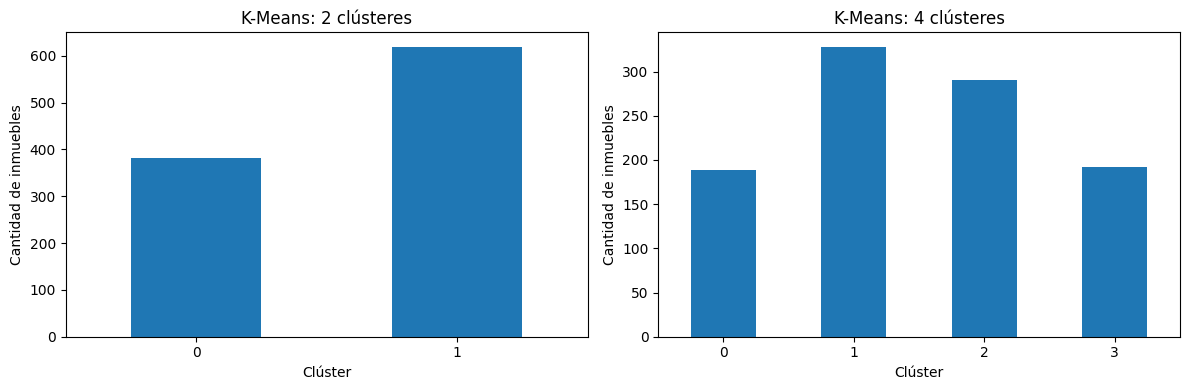

In [23]:
# Comparar la cantidad de inmuebles por clúster

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["Cluster_2"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="K-Means: 2 clústeres"
)
axes[0].set_xlabel("Clúster")
axes[0].set_ylabel("Cantidad de inmuebles")
axes[0].tick_params(axis="x", rotation=0)

df["Cluster_4"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="K-Means: 4 clústeres"
)
axes[1].set_xlabel("Clúster")
axes[1].set_ylabel("Cantidad de inmuebles")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Análisis de la distribución de los clústeres

La visualización permite comparar la cantidad de inmuebles asignados a cada grupo en los dos modelos. Con dos clústeres se obtuvieron grupos de 381 y 619 registros, mientras que con cuatro clústeres se formaron grupos de 189, 328, 291 y 192 inmuebles. La configuración de cuatro grupos proporciona una división más detallada del portafolio, aunque su utilidad comercial debe evaluarse considerando las características de cada segmento y no únicamente su tamaño.


### Comparación del precio promedio por clúster

Se analiza el precio promedio de arriendo de los inmuebles en cada grupo para identificar diferencias económicas entre los segmentos. La comparación permite evaluar cómo cambia la distribución comercial al pasar de dos a cuatro clústeres y complementa la información obtenida mediante las estadísticas descriptivas.

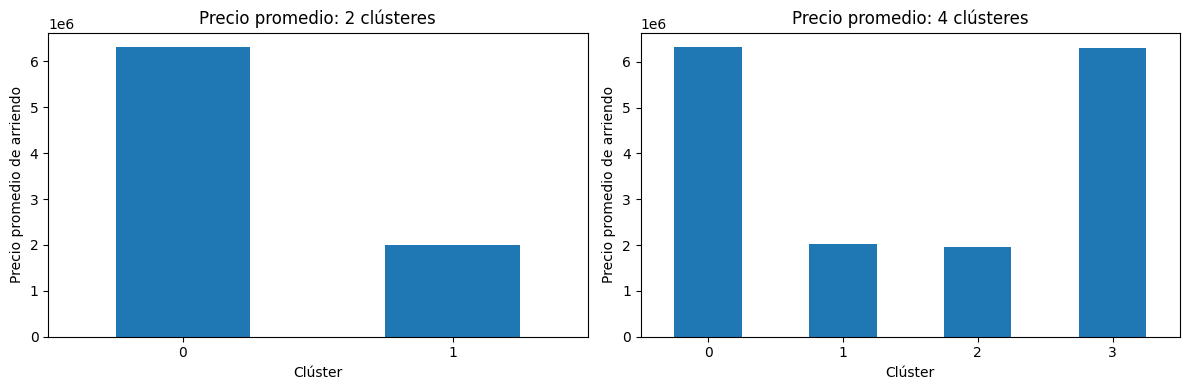

In [24]:
# Comparar el precio promedio de arriendo por clúster

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.groupby("Cluster_2")["Precio arriendo"].mean().plot(
    kind="bar", ax=axes[0], title="Precio promedio: 2 clústeres"
)
axes[0].set_xlabel("Clúster")
axes[0].set_ylabel("Precio promedio de arriendo")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("Cluster_4")["Precio arriendo"].mean().plot(
    kind="bar", ax=axes[1], title="Precio promedio: 4 clústeres"
)
axes[1].set_xlabel("Clúster")
axes[1].set_ylabel("Precio promedio de arriendo")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Comparación del precio promedio de arriendo

La comparación gráfica muestra una diferencia económica marcada entre los dos grupos del modelo con dos clústeres. Al utilizar cuatro clústeres, se observa que los grupos 0 y 3 presentan precios promedio elevados, mientras que los grupos 1 y 2 registran precios promedio inferiores. Esto sugiere que la segmentación más detallada conserva dos perfiles generales de precio, por lo que es necesario examinar otras características para determinar si los cuatro grupos aportan diferencias comerciales relevantes.

### Análisis de variables categóricas por clúster

Se examina la distribución de las localidades y los tipos de inmueble dentro de los cuatro grupos identificados por K-Means. Esta comparación complementa las estadísticas numéricas y permite evaluar si los segmentos presentan diferencias geográficas o relacionadas con el tipo de propiedad.

In [25]:
# Distribución de localidades por clúster
print("Localidad por clúster:")
display(pd.crosstab(df["Cluster_4"], df["Localidad"]))

# Distribución de tipos de inmueble por clúster
print("Tipo de inmueble por clúster:")
display(pd.crosstab(df["Cluster_4"], df["Tipo Inmueble"]))

Localidad por clúster:


Localidad,Chapinero,Suba,Usaquén
Cluster_4,,,
0,53,59,77
1,112,114,102
2,105,101,85
3,63,60,69


Tipo de inmueble por clúster:


Tipo Inmueble,ApartaEstudio,Apto,Casa
Cluster_4,,,
0,77,59,53
1,102,114,112
2,85,101,105
3,69,60,63


### Interpretación de las variables categóricas

La revisión de las tablas cruzadas muestra que los cuatro clústeres contienen inmuebles de las tres localidades y de los tres tipos de propiedad considerados. No se identifican grupos exclusivos por ubicación o tipo de inmueble. En consecuencia, las diferencias observadas en la segmentación parecen estar asociadas principalmente con las características físicas y económicas, aunque se requiere complementar el análisis con proporciones y otras medidas para evaluar la contribución de las variables categóricas.

### Método del codo

Se aplica el método del codo para examinar cómo cambia la inercia al aumentar el número de clústeres. La gráfica permite identificar si existe un punto a partir del cual agregar nuevos grupos produce reducciones cada vez menores en la dispersión interna. Este análisis complementa la comparación entre dos y cuatro clústeres, sin sustituir la interpretación comercial de los segmentos.

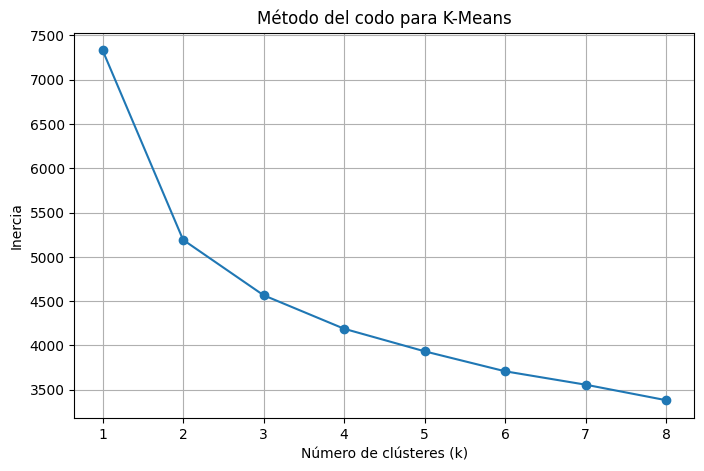

In [26]:
# Evaluar la inercia para diferentes cantidades de clústeres

inercias = []

for k in range(1, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    modelo.fit(X_escalado)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), inercias, marker="o")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.title("Método del codo para K-Means")
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()

### Interpretación del método del codo

La gráfica muestra una reducción pronunciada de la inercia entre uno y tres clústeres. A partir de aproximadamente tres o cuatro grupos, la curva presenta una disminución más gradual. Este comportamiento sugiere que el punto de inflexión podría encontrarse en ese intervalo. Por ello, se considera pertinente comparar las soluciones de dos y cuatro clústeres, teniendo en cuenta tanto la compactación de los grupos como su utilidad comercial.

## Análisis de Componentes Principales (PCA)

El Análisis de Componentes Principales es una técnica de reducción de dimensionalidad que transforma un conjunto de variables en componentes que resumen la variabilidad de los datos. En esta actividad se utilizará PCA para representar las características de los inmuebles mediante un número menor de dimensiones, estudiar la varianza explicada y visualizar los grupos identificados mediante K-Means.

### Preparación e implementación de PCA

Se utilizará el Análisis de Componentes Principales para reducir las 12 características preparadas previamente a dos componentes principales. Para mantener la coherencia con el análisis de K-Means, se empleará la matriz `X_escalado`, que contiene las variables numéricas estandarizadas y las variables categóricas codificadas. Posteriormente, se analizará la proporción de varianza explicada por cada componente.

In [27]:
from sklearn.decomposition import PCA

# Aplicar PCA para reducir los datos a dos dimensiones
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_escalado)

# Mostrar las dimensiones y la varianza explicada
print("Dimensiones originales:", X_escalado.shape)
print("Dimensiones después de PCA:", X_pca.shape)

print("\nVarianza explicada por componente:")
print(np.round(pca.explained_variance_ratio_, 4))

print("\nVarianza explicada acumulada:")
print(round(pca.explained_variance_ratio_.sum(), 4))

Dimensiones originales: (1000, 12)
Dimensiones después de PCA: (1000, 2)

Varianza explicada por componente:
[0.3492 0.1463]

Varianza explicada acumulada:
0.4955


### Interpretación de la varianza explicada por PCA

Se aplicó PCA para reducir las 12 características originales a dos componentes principales. El primer componente explicó el 34,92 % de la varianza y el segundo el 14,63 %, para una varianza explicada acumulada del 49,55 %. Esta reducción facilita la representación gráfica de los inmuebles en dos dimensiones, aunque conserva menos de la mitad de la variabilidad total del conjunto de datos. Por esta razón, la visualización debe interpretarse como una representación simplificada de la información original.

### Visualización de los resultados de PCA

Se representa cada inmueble mediante sus coordenadas en los dos componentes principales. Los puntos se colorean según el clúster asignado por K-Means con cuatro grupos, con el propósito de observar cómo se distribuyen los segmentos en el espacio reducido y evaluar visualmente su separación.

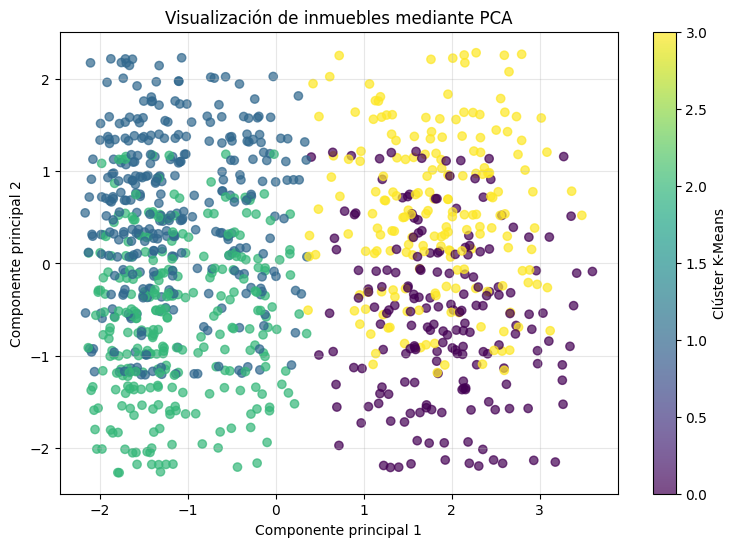

In [28]:
# Visualizar los cuatro clústeres en el espacio PCA

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=etiquetas_4,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Visualización de inmuebles mediante PCA")
plt.colorbar(label="Clúster K-Means")
plt.grid(True, alpha=0.3)
plt.show()

### Análisis de la varianza explicada acumulada

Para evaluar la información que puede conservarse al reducir la dimensionalidad, se analiza la varianza explicada acumulada de los componentes principales. Esto permite comparar la representación bidimensional con alternativas que utilizan un mayor número de componentes.

Varianza explicada acumulada por componente:
[0.3492 0.4955 0.631  0.7583 0.8492 0.9393 0.9726 1.     1.     1.
 1.     1.    ]


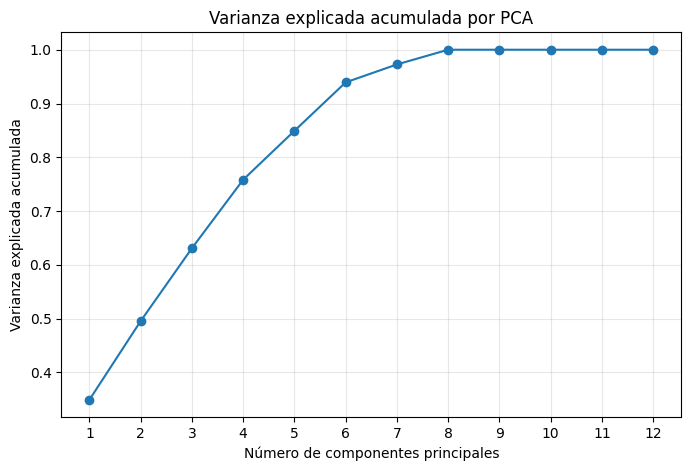

In [29]:
# Analizar la varianza explicada acumulada

pca_completo = PCA()
pca_completo.fit(X_escalado)

varianza_acumulada = np.cumsum(
    pca_completo.explained_variance_ratio_
)

print("Varianza explicada acumulada por componente:")
print(np.round(varianza_acumulada, 4))

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker="o"
)
plt.xlabel("Número de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada por PCA")
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.grid(True, alpha=0.3)
plt.show()

### Interpretación de la varianza explicada acumulada

La gráfica muestra que la varianza explicada acumulada aumenta a medida que se incorporan componentes principales. Los dos primeros componentes representan el 49,55 % de la variabilidad total, mientras que con cuatro componentes se alcanza aproximadamente el 75,83 %. Con seis componentes, la varianza acumulada es cercana al 93,97 %. Estos resultados muestran que una representación con pocas dimensiones facilita la visualización, aunque conservar un mayor porcentaje de la información requiere incorporar más componentes.

### Reducción de dimensionalidad mediante SVD

La Descomposición en Valores Singulares (SVD) es una técnica de álgebra lineal que permite descomponer una matriz en componentes que pueden utilizarse para analizar su estructura y obtener representaciones de menor dimensión. En esta actividad se aplicará SVD a la matriz de características preprocesadas para comparar su representación reducida con la obtenida mediante PCA.

In [31]:
from sklearn.decomposition import TruncatedSVD

# Aplicar SVD para obtener una representación de dos dimensiones
svd = TruncatedSVD(n_components=2, random_state=42)

X_svd = svd.fit_transform(X_escalado)

print("Dimensiones originales:", X_escalado.shape)
print("Dimensiones después de SVD:", X_svd.shape)

print("\nVarianza explicada por componente:")
print(np.round(svd.explained_variance_ratio_, 4))

print("\nVarianza explicada acumulada:")
print(round(svd.explained_variance_ratio_.sum(), 4))

Dimensiones originales: (1000, 12)
Dimensiones después de SVD: (1000, 2)

Varianza explicada por componente:
[0.3492 0.1463]

Varianza explicada acumulada:
0.4955


### Interpretación de los resultados de SVD

Se aplicó TruncatedSVD para reducir la matriz de 12 características a dos componentes, manteniendo los 1.000 registros. La salida reportó una varianza explicada acumulada del 49,55 %, coincidente con el resultado obtenido mediante PCA en este ejercicio. Esta representación facilita la visualización de los datos en dos dimensiones, aunque no conserva toda la variabilidad del conjunto original.

### Comparación de PCA y SVD

Se comparan las proporciones de varianza explicada obtenidas mediante PCA y TruncatedSVD, utilizando dos componentes principales en cada caso. La comparación permite observar la información representada por cada técnica en el espacio reducido de dos dimensiones.

In [32]:
# Comparar la varianza explicada de PCA y SVD

comparacion_reduccion = pd.DataFrame({
    "Método": ["PCA", "TruncatedSVD"],
    "Componente 1": [
        pca.explained_variance_ratio_[0],
        svd.explained_variance_ratio_[0]
    ],
    "Componente 2": [
        pca.explained_variance_ratio_[1],
        svd.explained_variance_ratio_[1]
    ],
    "Varianza acumulada": [
        pca.explained_variance_ratio_.sum(),
        svd.explained_variance_ratio_.sum()
    ]
})

display(comparacion_reduccion.round(4))

,Método,Componente 1,Componente 2,Varianza acumulada
0,PCA,0.3492,0.1463,0.4955
1,TruncatedSVD,0.3492,0.1463,0.4955


### Verificación de las representaciones PCA y SVD

Se realiza una comprobación adicional para comparar las coordenadas obtenidas mediante PCA y TruncatedSVD. Este procedimiento permite verificar si las representaciones bidimensionales coinciden numéricamente o si existen diferencias entre los métodos, más allá de los porcentajes de varianza explicada reportados.

In [33]:
# Comparar las primeras coordenadas de PCA y SVD

print("Primeros cinco registros de PCA:")
print(np.round(X_pca[:5], 4))

print("\nPrimeros cinco registros de SVD:")
print(np.round(X_svd[:5], 4))

Primeros cinco registros de PCA:
[[-1.1908 -0.3107]
 [-1.9984  0.1155]
 [ 2.7941  1.3318]
 [-0.3098  1.572 ]
 [-1.8766  2.2143]]

Primeros cinco registros de SVD:
[[-1.1909 -0.3107]
 [-1.9984  0.1155]
 [ 2.7941  1.3318]
 [-0.3099  1.572 ]
 [-1.8767  2.2143]]


### Verificación de las coordenadas PCA y SVD

La comparación de las primeras coordenadas obtenidas mediante PCA y TruncatedSVD muestra resultados muy similares, con pequeñas diferencias en algunos valores. Estas diferencias pueden relacionarse con la orientación de los componentes calculados. Por ello, la comparación de ambos métodos debe considerar tanto las coordenadas obtenidas como la varianza explicada y el procedimiento de transformación aplicado.